# Customer Retention

## Ruang lingkup dan keputusan analitis

- **Welch's independent two-sample t-test** menjadi baseline untuk membandingkan rata-rata revenue dua kelompok promosi tanpa mengasumsikan varians kedua kelompok sama.
- **OLS multiple linear regression** digunakan untuk mengestimasi hubungan `Daily_Ad_Spend` dengan `Website_Traffic`, sambil mengendalikan region, jenis promosi, dan hari dalam minggu.
- Data memiliki enam region pada tanggal yang sama. Karena observasi pada tanggal yang sama mungkin saling berkaitan, inferensi regresi memakai **date-clustered standard errors**.
- Baris dengan `Flag_Anomali` selain `Normal` tidak dihapus dari workbook. Analisis utama menggunakan baris `Normal`, sementara hasil dengan seluruh baris ditampilkan sebagai sensitivity check.
- `Ad_Spend_Diimputasi` dipakai untuk sensitivity check tambahan agar pengaruh nilai ad spend hasil imputasi dapat dinilai.
- Hasil regresi bersifat **asosiasi**, bukan bukti sebab-akibat. Data observasional ini tidak otomatis membuktikan bahwa penambahan iklan akan menyebabkan tambahan traffic sebesar koefisien model.
- Workbook tidak memiliki identitas pelanggan dan riwayat pembelian per pelanggan. Karena itu, notebook tidak mengarang angka retention rate atau churn; keterbatasan ini dibahas pada bagian akhir.

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linewidth": 0.6,
    "axes.titleweight": "semibold",
    "axes.labelcolor": "#333333",
    "text.color": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

## 1. Upload workbook Excel

In [ ]:
file_path = None

try:
    from google.colab import files
    uploaded_files = files.upload()
    if uploaded_files:
        file_path = next(iter(uploaded_files))
except ImportError:
    default_path = Path("marketing_campaign_logs_cleaned.xlsx")
    excel_files = sorted(Path.cwd().glob("*.xlsx"))
    if default_path.exists():
        file_path = str(default_path)
    elif len(excel_files) == 1:
        file_path = str(excel_files[0])

if file_path is None or not Path(file_path).is_file():
    raise FileNotFoundError("File Excel belum ditemukan. Upload file di Google Colab atau letakkan marketing_campaign_logs_cleaned.xlsx di folder kerja notebook.")

print(f"File siap digunakan: {Path(file_path).name}")

File siap digunakan: marketing_campaign_logs_cleaned.xlsx


## 2. Membaca data yang telah dibersihkan

In [ ]:
df = pd.read_excel(file_path, sheet_name="Data Cleaning")

required_columns = [
    "Tanggal",
    "Region_Code",
    "Promo_Active",
    "Daily_Ad_Spend",
    "Website_Traffic",
    "Daily_Revenue",
    "Ad_Spend_Diimputasi",
    "Flag_Anomali",
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

df = df[required_columns].copy()
df["Tanggal"] = pd.to_datetime(df["Tanggal"], errors="raise")
for column in ["Region_Code", "Promo_Active", "Ad_Spend_Diimputasi", "Flag_Anomali"]:
    df[column] = df[column].astype("string").str.strip()
for column in ["Daily_Ad_Spend", "Website_Traffic", "Daily_Revenue"]:
    df[column] = pd.to_numeric(df[column], errors="raise")

display(df.head())
print(f"\nUkuran data: {df.shape[0]:,} baris × {df.shape[1]} kolom")

,Tanggal,Region_Code,Promo_Active,Daily_Ad_Spend,Website_Traffic,Daily_Revenue,Ad_Spend_Diimputasi,Flag_Anomali
0,2023-07-01,BALI,Diskon 20%,1357228,2381,33940810,Tidak,Normal
1,2023-07-01,JABODETABEK,Diskon 20%,2025073,9476,84768237,Tidak,Normal
2,2023-07-01,JAWA BARAT,Cashback 50K,2920469,7690,55800115,Tidak,Normal
3,2023-07-01,JAWA TIMUR,Diskon 20%,2164506,6158,77552939,Tidak,Normal
4,2023-07-01,SULAWESI,Diskon 20%,3354172,4768,56331577,Tidak,Normal



Ukuran data: 1,104 baris × 8 kolom


## 3. Audit data dan penentuan sampel analisis

Audit ini memastikan jumlah observasi, rentang tanggal, kelengkapan kolom, keunikan kombinasi tanggal-region, serta penanda anomali dan imputasi. Sampel utama dibatasi ke baris yang telah diberi label `Normal` seluruh baris tetap dipakai pada pemeriksaan sensitivitas.

In [ ]:
daily_counts = df.groupby("Tanggal").size()
required_numeric = ["Daily_Ad_Spend", "Website_Traffic", "Daily_Revenue"]

audit = pd.DataFrame({
    "Pemeriksaan": [
        "Jumlah baris",
        "Jumlah kolom",
        "Tanggal paling awal",
        "Tanggal paling akhir",
        "Jumlah tanggal unik",
        "Jumlah region unik",
        "Jumlah missing values",
        "Duplikat seluruh baris",
        "Duplikat kombinasi tanggal-region",
        "Baris berlabel anomali",
        "Baris ad spend hasil imputasi",
        "Tanggal dengan 6 observasi region",
    ],
    "Hasil": [
        f"{len(df):,}",
        f"{df.shape[1]:,}",
        df["Tanggal"].min().strftime("%Y-%m-%d"),
        df["Tanggal"].max().strftime("%Y-%m-%d"),
        f"{df['Tanggal'].nunique():,}",
        f"{df['Region_Code'].nunique():,}",
        f"{int(df.isna().sum().sum()):,}",
        f"{int(df.duplicated().sum()):,}",
        f"{int(df.duplicated(['Tanggal', 'Region_Code']).sum()):,}",
        f"{int(df['Flag_Anomali'].ne('Normal').sum()):,}",
        f"{int(df['Ad_Spend_Diimputasi'].eq('Ya').sum()):,}",
        f"{int(daily_counts.eq(6).sum()):,} dari {len(daily_counts):,} tanggal",
    ],
})
display(audit)

print("Distribusi promo:")
display(df["Promo_Active"].value_counts(dropna=False).rename_axis("Promo_Active").reset_index(name="Jumlah baris"))
print("Distribusi flag anomali:")
display(df["Flag_Anomali"].value_counts(dropna=False).rename_axis("Flag_Anomali").reset_index(name="Jumlah baris"))
print("Distribusi flag imputasi ad spend:")
display(df["Ad_Spend_Diimputasi"].value_counts(dropna=False).rename_axis("Ad_Spend_Diimputasi").reset_index(name="Jumlah baris"))

if df[required_numeric].isna().any().any():
    raise ValueError("Kolom numerik masih memiliki missing values. Periksa proses cleaning sebelum melanjutkan.")
if df[["Tanggal", "Region_Code", "Promo_Active", "Flag_Anomali"]].isna().any().any():
    raise ValueError("Kolom identitas analisis atau kategori masih memiliki missing values.")

normal_mask = df["Flag_Anomali"].eq("Normal")
df_normal = df.loc[normal_mask].copy()
df_no_imputed = df_normal.loc[df_normal["Ad_Spend_Diimputasi"].eq("Tidak")].copy()

print(f"\nSampel utama (Normal): {len(df_normal):,} baris")
print(f"Sampel seluruh baris untuk sensitivity check: {len(df):,} baris")
print(f"Sampel utama tanpa ad spend imputasi: {len(df_no_imputed):,} baris")

,Pemeriksaan,Hasil
0,Jumlah baris,"1,104"
1,Jumlah kolom,8
2,Tanggal paling awal,2023-07-01
3,Tanggal paling akhir,2023-12-31
4,Jumlah tanggal unik,184
5,Jumlah region unik,6
6,Jumlah missing values,0
7,Duplikat seluruh baris,0
8,Duplikat kombinasi tanggal-region,0
9,Baris berlabel anomali,17


Distribusi promo:


,Promo_Active,Jumlah baris
0,Diskon 20%,588
1,Cashback 50K,516


Distribusi flag anomali:


,Flag_Anomali,Jumlah baris
0,Normal,1087
1,"Anomali (traffic tinggi, revenue sangat rendah)",17


Distribusi flag imputasi ad spend:


,Ad_Spend_Diimputasi,Jumlah baris
0,Tidak,1060
1,Ya,44



Sampel utama (Normal): 1,087 baris
Sampel seluruh baris untuk sensitivity check: 1,104 baris
Sampel utama tanpa ad spend imputasi: 1,043 baris


## 4. Statistik deskriptif

In [ ]:
summary_by_promo = (
    df_normal.assign(Daily_Revenue_Million=df_normal["Daily_Revenue"] / 1_000_000)
    .groupby("Promo_Active")
    .agg(
        Jumlah_observasi=("Daily_Revenue", "size"),
        Rata_rata_revenue_juta=("Daily_Revenue_Million", "mean"),
        Median_revenue_juta=("Daily_Revenue_Million", "median"),
        Std_revenue_juta=("Daily_Revenue_Million", "std"),
        Rata_rata_traffic=("Website_Traffic", "mean"),
        Rata_rata_ad_spend=("Daily_Ad_Spend", "mean"),
    )
    .reset_index()
)
display(summary_by_promo)

numeric_summary = df_normal[["Daily_Ad_Spend", "Website_Traffic", "Daily_Revenue"]].describe().T
numeric_summary.index.name = "Variabel"
display(numeric_summary)

,Promo_Active,Jumlah_observasi,Rata_rata_revenue_juta,Median_revenue_juta,Std_revenue_juta,Rata_rata_traffic,Rata_rata_ad_spend
0,Cashback 50K,505,42.824,38.062,24.284,"5,939.513","2,746,201.998"
1,Diskon 20%,582,68.715,62.197,36.857,"5,729.682","2,680,450.134"


,count,mean,std,min,25%,50%,75%,max
Variabel,,,,,,,,
Daily_Ad_Spend,"1,087.000","2,710,997.228","1,302,974.556","505,203.000","1,588,696.000","2,665,099.000","3,818,902.000","4,992,336.000"
Website_Traffic,"1,087.000","5,827.166","3,019.652","1,143.000","3,557.000","5,278.000","7,449.000","19,176.000"
Daily_Revenue,"1,087.000","56,686,450.720","34,166,066.252","5,240,640.000","31,573,106.500","47,781,053.000","74,998,871.000","227,393,918.000"


## 5. Task A — Welch's independent two-sample t-test

In [ ]:
def welch_test_summary(data, group_a="Diskon 20%", group_b="Cashback 50K", value_column="Daily_Revenue", alpha=0.05):
    values_a = data.loc[data["Promo_Active"].eq(group_a), value_column].dropna().astype(float)
    values_b = data.loc[data["Promo_Active"].eq(group_b), value_column].dropna().astype(float)

    test = stats.ttest_ind(values_a, values_b, equal_var=False, alternative="two-sided")
    n_a = len(values_a)
    n_b = len(values_b)
    mean_a = values_a.mean()
    mean_b = values_b.mean()
    variance_a = values_a.var(ddof=1)
    variance_b = values_b.var(ddof=1)
    mean_difference = mean_a - mean_b
    standard_error = np.sqrt(variance_a / n_a + variance_b / n_b)
    degrees_freedom = (variance_a / n_a + variance_b / n_b) ** 2 / (
        (variance_a / n_a) ** 2 / (n_a - 1) + (variance_b / n_b) ** 2 / (n_b - 1)
    )
    critical_value = stats.t.ppf(1 - alpha / 2, degrees_freedom)
    ci_low = mean_difference - critical_value * standard_error
    ci_high = mean_difference + critical_value * standard_error
    pooled_variance = ((n_a - 1) * variance_a + (n_b - 1) * variance_b) / (n_a + n_b - 2)
    cohen_d = mean_difference / np.sqrt(pooled_variance)

    return {
        "n_diskon": n_a,
        "n_cashback": n_b,
        "mean_diskon": mean_a,
        "mean_cashback": mean_b,
        "mean_difference": mean_difference,
        "t_statistic": float(test.statistic),
        "p_value": float(test.pvalue),
        "degrees_freedom": float(degrees_freedom),
        "ci_low": ci_low,
        "ci_high": ci_high,
        "cohen_d": cohen_d,
        "decision": "Tolak H₀" if test.pvalue < alpha else "Gagal menolak H₀",
    }

def format_pvalue(value):
    return "< 0,001" if value < 0.001 else f"{value:.3f}".replace(".", ",")

def format_rupiah(value, decimals=0):
    if decimals == 0:
        return "Rp " + f"{value:,.0f}".replace(",", ".")
    return "Rp " + f"{value:,.{decimals}f}".replace(",", "X").replace(".", ",").replace("X", ".")

welch_primary = welch_test_summary(df_normal)
welch_all = welch_test_summary(df)

welch_table = pd.DataFrame([
    {
        "Sampel": "Utama — hanya baris Normal",
        "n Diskon": welch_primary["n_diskon"],
        "n Cashback": welch_primary["n_cashback"],
        "Rata-rata Diskon (Rp)": welch_primary["mean_diskon"],
        "Rata-rata Cashback (Rp)": welch_primary["mean_cashback"],
        "Selisih mean (Rp)": welch_primary["mean_difference"],
        "95% CI bawah (Rp)": welch_primary["ci_low"],
        "95% CI atas (Rp)": welch_primary["ci_high"],
        "t-statistic": welch_primary["t_statistic"],
        "p-value": welch_primary["p_value"],
        "Cohen's d": welch_primary["cohen_d"],
        "Keputusan α=0,05": welch_primary["decision"],
    },
    {
        "Sampel": "Sensitivity — seluruh baris",
        "n Diskon": welch_all["n_diskon"],
        "n Cashback": welch_all["n_cashback"],
        "Rata-rata Diskon (Rp)": welch_all["mean_diskon"],
        "Rata-rata Cashback (Rp)": welch_all["mean_cashback"],
        "Selisih mean (Rp)": welch_all["mean_difference"],
        "95% CI bawah (Rp)": welch_all["ci_low"],
        "95% CI atas (Rp)": welch_all["ci_high"],
        "t-statistic": welch_all["t_statistic"],
        "p-value": welch_all["p_value"],
        "Cohen's d": welch_all["cohen_d"],
        "Keputusan α=0,05": welch_all["decision"],
    },
])
display(welch_table)

,Sampel,n Diskon,n Cashback,Rata-rata Diskon (Rp),Rata-rata Cashback (Rp),Selisih mean (Rp),95% CI bawah (Rp),95% CI atas (Rp),t-statistic,p-value,Cohen's d,"Keputusan α=0,05"
0,Utama — hanya baris Normal,582,505,"68,714,879.792","42,823,983.949","25,890,895.844","22,218,814.425","29,562,977.262",13.836,0.000,0.818,Tolak H₀
1,Sensitivity — seluruh baris,588,516,"68,017,244.757","41,918,202.886","26,099,041.871","22,397,347.061","29,800,736.681",13.835,0.000,0.814,Tolak H₀


### Visualisasi revenue per promosi

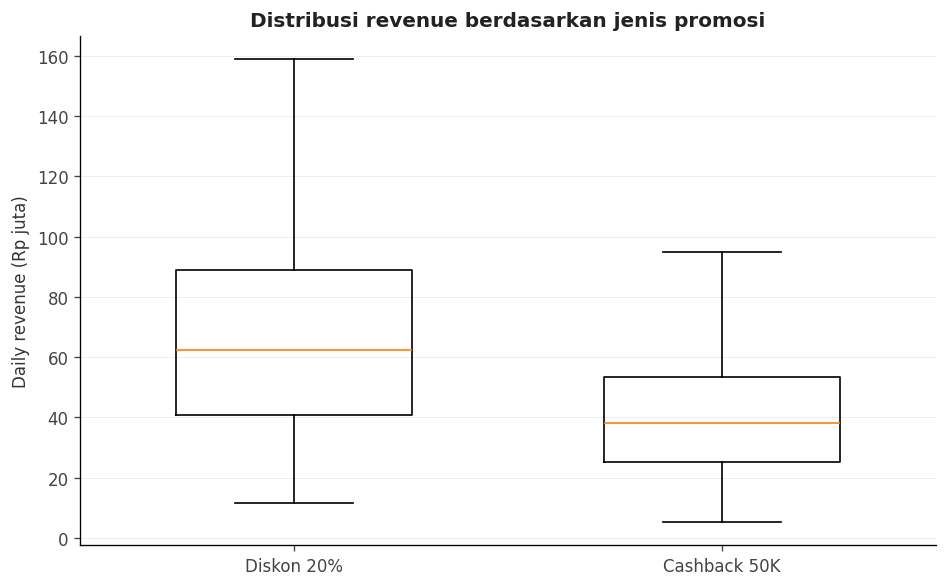

In [ ]:
promo_order = ["Diskon 20%", "Cashback 50K"]
revenue_data = [
    df_normal.loc[df_normal["Promo_Active"].eq(promo), "Daily_Revenue"] / 1_000_000
    for promo in promo_order
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(revenue_data, showfliers=False, widths=0.55)
ax.set_xticks([1, 2], labels=promo_order)
ax.set_ylabel("Daily revenue (Rp juta)")
ax.set_title("Distribusi revenue berdasarkan jenis promosi")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### Pemeriksaan tambahan untuk struktur data berulang

In [ ]:
revenue_model = smf.ols(
    "Daily_Revenue ~ C(Promo_Active) + C(Region_Code)",
    data=df_normal,
).fit(cov_type="cluster", cov_kwds={"groups": df_normal["Tanggal"]})

promo_term = "C(Promo_Active)[T.Diskon 20%]"
if promo_term not in revenue_model.params.index:
    raise ValueError("Koefisien promo Diskon 20% tidak ditemukan. Periksa label pada Promo_Active.")

promo_ci = revenue_model.conf_int().loc[promo_term]
promo_cluster_result = pd.DataFrame([{
    "Estimasi selisih Diskon vs Cashback (Rp)": revenue_model.params[promo_term],
    "Standard error (cluster tanggal)": revenue_model.bse[promo_term],
    "95% CI bawah (Rp)": promo_ci.iloc[0],
    "95% CI atas (Rp)": promo_ci.iloc[1],
    "p-value": revenue_model.pvalues[promo_term],
    "R-squared model": revenue_model.rsquared,
    "Jumlah observasi": int(revenue_model.nobs),
}])
display(promo_cluster_result)

print("Rangkuman inferensi:")
print(f"Welch t-test: p-value {format_pvalue(welch_primary['p_value'])}; keputusan {welch_primary['decision']} pada α = 0,05.")
print(f"Model dengan kontrol region dan cluster tanggal: p-value {format_pvalue(revenue_model.pvalues[promo_term])}.")

,Estimasi selisih Diskon vs Cashback (Rp),Standard error (cluster tanggal),95% CI bawah (Rp),95% CI atas (Rp),p-value,R-squared model,Jumlah observasi
0,"26,088,701.474","1,679,340.093","22,797,255.375","29,380,147.574",0.000,0.296,1087


Rangkuman inferensi:
Welch t-test: p-value < 0,001; keputusan Tolak H₀ pada α = 0,05.
Model dengan kontrol region dan cluster tanggal: p-value < 0,001.


## 6. Task B — OLS multiple linear regression untuk traffic

In [ ]:
def fit_traffic_model(data):
    model_data = data.copy()
    model_data["Ad_Spend_Million"] = model_data["Daily_Ad_Spend"] / 1_000_000
    model_data["DayOfWeek"] = model_data["Tanggal"].dt.dayofweek
    fitted_model = smf.ols(
        "Website_Traffic ~ Ad_Spend_Million + C(Region_Code) + C(Promo_Active) + C(DayOfWeek)",
        data=model_data,
    ).fit(cov_type="cluster", cov_kwds={"groups": model_data["Tanggal"]})
    return fitted_model, model_data

traffic_model, traffic_model_data = fit_traffic_model(df_normal)
traffic_term = "Ad_Spend_Million"
traffic_ci = traffic_model.conf_int().loc[traffic_term]
traffic_beta = traffic_model.params[traffic_term]
traffic_p = traffic_model.pvalues[traffic_term]

traffic_model_summary = pd.DataFrame([
    {"Metrik": "Observasi model", "Nilai": int(traffic_model.nobs)},
    {"Metrik": "Koefisien ad spend per Rp1 juta", "Nilai": traffic_beta},
    {"Metrik": "Cluster-robust standard error", "Nilai": traffic_model.bse[traffic_term]},
    {"Metrik": "95% CI bawah koefisien", "Nilai": traffic_ci.iloc[0]},
    {"Metrik": "95% CI atas koefisien", "Nilai": traffic_ci.iloc[1]},
    {"Metrik": "p-value koefisien ad spend", "Nilai": traffic_p},
    {"Metrik": "R-squared keseluruhan model", "Nilai": traffic_model.rsquared},
    {"Metrik": "Adjusted R-squared", "Nilai": traffic_model.rsquared_adj},
])
display(traffic_model_summary)

,Metrik,Nilai
0,Observasi model,"1,087.000"
1,Koefisien ad spend per Rp1 juta,"1,716.117"
2,Cluster-robust standard error,37.855
3,95% CI bawah koefisien,"1,641.923"
4,95% CI atas koefisien,"1,790.310"
5,p-value koefisien ad spend,0.000
6,R-squared keseluruhan model,0.749
7,Adjusted R-squared,0.746


### Sensitivity check model traffic

Koefisien dibandingkan pada tiga skenario: (1) sampel utama dengan baris `Normal`, (2) seluruh baris termasuk yang ditandai anomali, dan (3) sampel utama tanpa baris ad spend hasil imputasi

In [ ]:
traffic_model_all, traffic_data_all = fit_traffic_model(df)
traffic_model_no_imputed, traffic_data_no_imputed = fit_traffic_model(df_no_imputed)

sensitivity_rows = []
for label, fitted_model in [
    ("Utama — hanya Normal", traffic_model),
    ("Sensitivity — semua baris", traffic_model_all),
    ("Sensitivity — Normal, tanpa imputasi", traffic_model_no_imputed),
]:
    ci = fitted_model.conf_int().loc[traffic_term]
    sensitivity_rows.append({
        "Skenario": label,
        "Observasi": int(fitted_model.nobs),
        "Koefisien per Rp1 juta": fitted_model.params[traffic_term],
        "95% CI bawah": ci.iloc[0],
        "95% CI atas": ci.iloc[1],
        "p-value": fitted_model.pvalues[traffic_term],
        "R-squared": fitted_model.rsquared,
    })

traffic_sensitivity = pd.DataFrame(sensitivity_rows)
display(traffic_sensitivity)

,Skenario,Observasi,Koefisien per Rp1 juta,95% CI bawah,95% CI atas,p-value,R-squared
0,Utama — hanya Normal,1087,"1,716.117","1,641.923","1,790.310",0.000,0.749
1,Sensitivity — semua baris,1104,"2,031.707","1,668.005","2,395.410",0.000,0.100
2,"Sensitivity — Normal, tanpa imputasi",1043,"1,719.606","1,644.969","1,794.244",0.000,0.769


### Visualisasi hubungan ad spend dan traffic

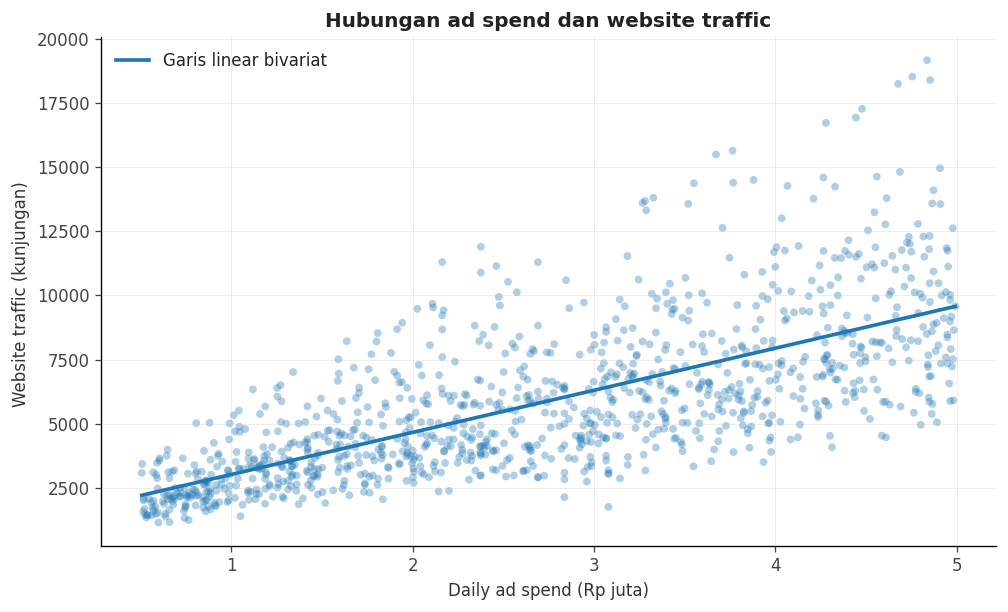

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(
    traffic_model_data["Ad_Spend_Million"],
    traffic_model_data["Website_Traffic"],
    s=22,
    alpha=0.35,
    edgecolors="none",
)
line_x = np.linspace(traffic_model_data["Ad_Spend_Million"].min(), traffic_model_data["Ad_Spend_Million"].max(), 120)
line_slope, line_intercept = np.polyfit(
    traffic_model_data["Ad_Spend_Million"],
    traffic_model_data["Website_Traffic"],
    1,
)
ax.plot(line_x, line_intercept + line_slope * line_x, linewidth=2.2, label="Garis linear bivariat")
ax.set_xlabel("Daily ad spend (Rp juta)")
ax.set_ylabel("Website traffic (kunjungan) ")
ax.set_title("Hubungan ad spend dan website traffic")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Pola traffic sepanjang waktu

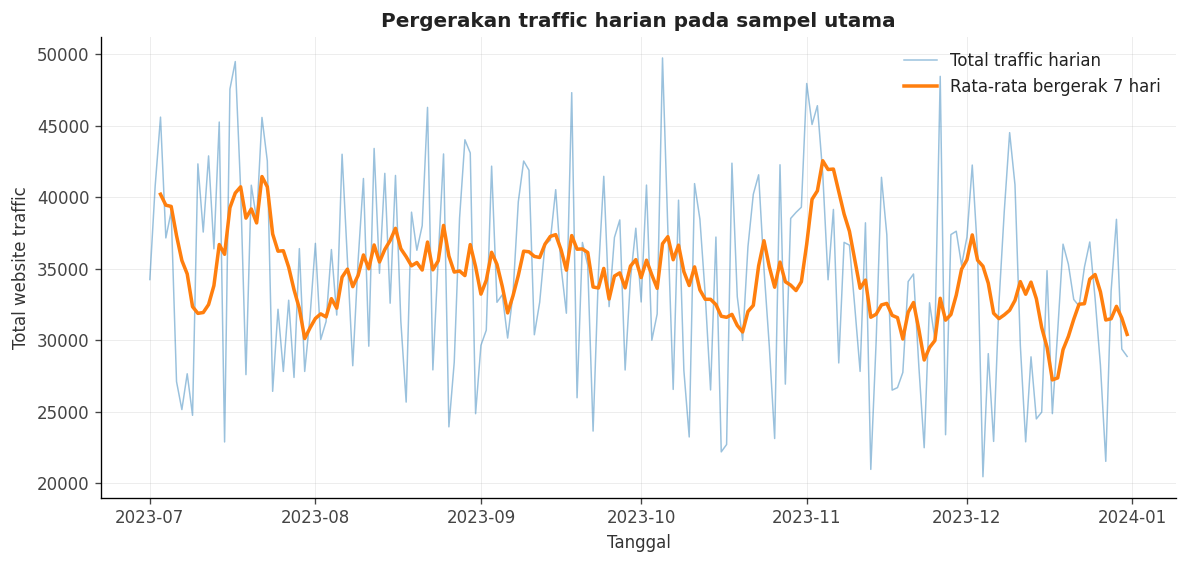

In [ ]:
daily_traffic = df_normal.groupby("Tanggal")["Website_Traffic"].sum().sort_index()
daily_traffic_rolling = daily_traffic.rolling(7, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(daily_traffic.index, daily_traffic.values, linewidth=0.9, alpha=0.45, label="Total traffic harian")
ax.plot(daily_traffic_rolling.index, daily_traffic_rolling.values, linewidth=2.1, label="Rata-rata bergerak 7 hari")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Total website traffic")
ax.set_title("Pergerakan traffic harian pada sampel utama")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Pemeriksaan residual model

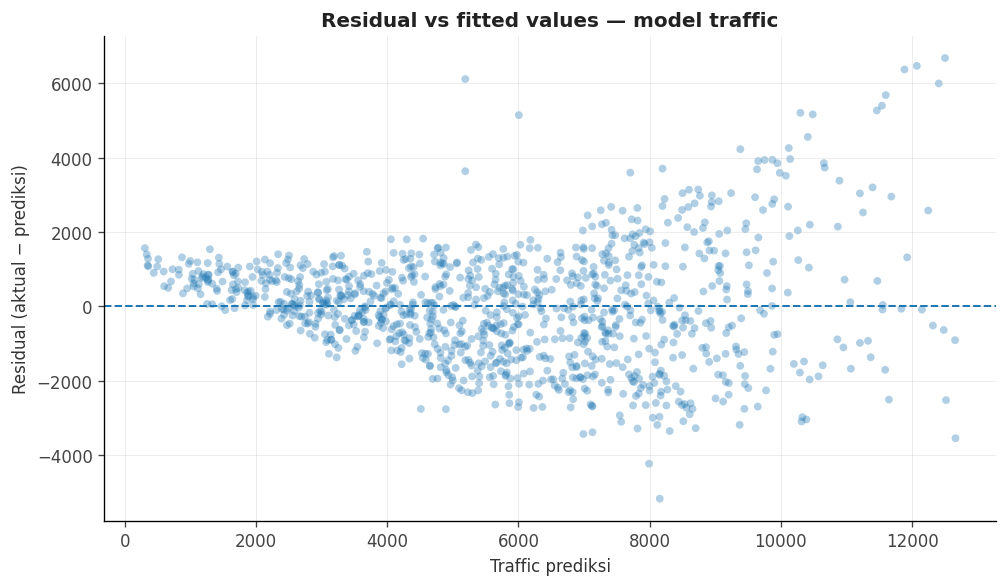

,Pemeriksaan,Nilai
0,Breusch–Pagan LM statistic,211.276
1,Breusch–Pagan p-value,0.000
2,Breusch–Pagan F statistic,19.913
3,Breusch–Pagan F p-value,0.000


Interpretasi: terdapat indikasi heteroskedastisitas pada residual. Standard error yang dikelompokkan berdasarkan tanggal tetap dipakai untuk inferensi utama.


In [ ]:
residuals = traffic_model.resid
fitted_values = traffic_model.fittedvalues

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(fitted_values, residuals, s=22, alpha=0.35, edgecolors="none")
ax.axhline(0, linewidth=1.2, linestyle="--")
ax.set_xlabel("Traffic prediksi")
ax.set_ylabel("Residual (aktual − prediksi)")
ax.set_title("Residual vs fitted values — model traffic")
fig.tight_layout()
plt.show()

bp_lm, bp_lm_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(traffic_model.resid, traffic_model.model.exog)
diagnostic_table = pd.DataFrame([
    {"Pemeriksaan": "Breusch–Pagan LM statistic", "Nilai": bp_lm},
    {"Pemeriksaan": "Breusch–Pagan p-value", "Nilai": bp_lm_pvalue},
    {"Pemeriksaan": "Breusch–Pagan F statistic", "Nilai": bp_f},
    {"Pemeriksaan": "Breusch–Pagan F p-value", "Nilai": bp_f_pvalue},
])
display(diagnostic_table)

if bp_lm_pvalue < 0.05:
    print("Interpretasi: terdapat indikasi heteroskedastisitas pada residual. Standard error yang dikelompokkan berdasarkan tanggal tetap dipakai untuk inferensi utama.")
else:
    print("Interpretasi: uji Breusch–Pagan tidak menunjukkan bukti kuat heteroskedastisitas pada ambang 0,05. Standard error berkelompok berdasarkan tanggal tetap dipakai karena struktur panel harian.")

## 7. Simulasi skenario tambahan anggaran

Tabel berikut menerjemahkan koefisien model utama ke beberapa skenario kenaikan biaya iklan. Nilai traffic dan interval kepercayaan diskalakan secara linear dari koefisien yang diestimasi. Angka ini adalah **estimasi asosiasi bersyarat**, bukan jaminan dampak kausal atau hasil eksperimen.

In [ ]:
budget_increases = [250_000, 500_000, 1_000_000]
scenario_rows = []
for amount in budget_increases:
    scale = amount / 1_000_000
    scenario_rows.append({
        "Tambahan ad spend": format_rupiah(amount),
        "Estimasi perubahan traffic": round(traffic_beta * scale),
        "95% CI bawah": round(traffic_ci.iloc[0] * scale),
        "95% CI atas": round(traffic_ci.iloc[1] * scale),
    })
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)

,Tambahan ad spend,Estimasi perubahan traffic,95% CI bawah,95% CI atas
0,Rp 250.000,429,410,448
1,Rp 500.000,858,821,895
2,Rp 1.000.000,1716,1642,1790
